In [1]:
# Install a pip package in the current Jupyter kernel
#import sys
#!{sys.executable} -m pip install tensorflow

In [2]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
np.set_printoptions(suppress=True, linewidth=200, edgeitems=100)
%matplotlib inline

#for text pre-processing
import re, string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')

# Pipeline and column transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer

# Data transformers
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, label_binarize, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Data splitter and model evaluator
from sklearn.model_selection import train_test_split, validation_curve, learning_curve, GridSearchCV

# Learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import BaggingClassifier, BaggingRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
#from xgboost import XGBClassifier, XGBRegressor  # Need to install

# Performance metrics
import sklearn.metrics

#Deep learning
import tensorflow as tf
from keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Activation
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing import sequence
import keras_tuner as kt

# bag of words
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer#for word embedding
import gensim
from gensim.models import Word2Vec


df_train = pd.read_csv('TrainDataSet.csv',low_memory=False)
#df_train['S-Protein'] = df_train['S-Protein'].astype(np.float32)
df_train.dtypes

[nltk_data] Downloading package punkt to C:\Users\Adhip
[nltk_data]     Maitra\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Adhip Maitra\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to C:\Users\Adhip
[nltk_data]     Maitra\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Identifier         object
S-Protein          object
Classification     object
Unnamed: 3        float64
dtype: object

In [3]:
list(df_train.columns)

['Identifier', 'S-Protein', 'Classification', 'Unnamed: 3']

In [4]:
df_train.shape

(1048534, 4)

In [5]:
df_train = df_train.drop(columns=['Unnamed: 3'])
list(df_train.columns)

['Identifier', 'S-Protein', 'Classification']

In [6]:
df_train=df_train.dropna()
df_train.shape

(104, 3)

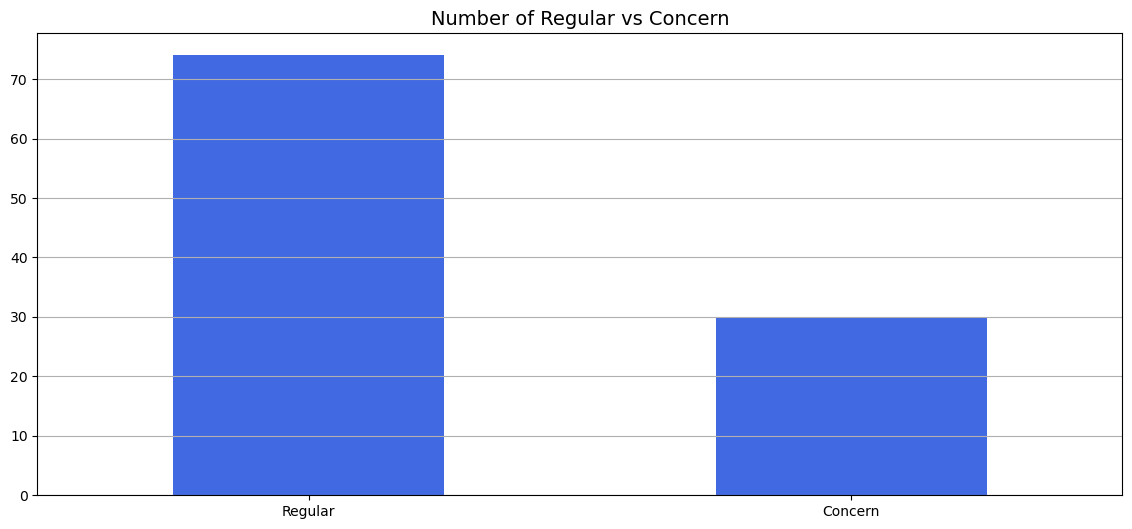

In [7]:
counts = df_train['Classification'].value_counts()
counts.plot(kind='bar', figsize=(14,6), color=['royalblue'])
plt.title('Number of Regular vs Concern', fontsize=14)
plt.grid(axis='y')
plt.xticks(rotation=0, fontsize=10)
plt.show()

In [8]:
df_train = df_train.replace('\n','', regex=True)
df_train['S-Protein'] = df_train['S-Protein'].str.strip(r'\\r')
print (df_train)

      Identifier                                          S-Protein  \
0    NC_045512.2  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
1       MZ437368  MFVFLVLLPLVSSQCVNLRTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
2       OM570262  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
3       QHR84449  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
4     QIX07431.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
..           ...                                                ...   
99    UST22952.1  MFVFLVLLPLVSSQCVNLITRTQSYTNSFTRGVYYPDKVFRSSVLH...   
100   QQV24132.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
101   QQV24885.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
102   QQV24803.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
103   QQV26579.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   

    Classification  
0          Regular  
1          Concern  
2          Concern  
3          Regular  
4          Regular  
..             ...  


In [9]:
# CHARACTER-COUNT
df_train['char_count'] = df_train['S-Protein'].apply(lambda x: len(str(x)))
print(df_train[df_train['Classification']=='Regular']['char_count'].mean()) #Regular
print(df_train[df_train['Classification']=='Concern']['char_count'].mean()) #Concern

1271.7837837837837
1269.9666666666667


In [10]:
X = df_train['S-Protein'].apply(str)
def split(word): 
    return [char for char in word]
sequences = [split(x) for x in X]
print(sequences[0])

['M', 'F', 'V', 'F', 'L', 'V', 'L', 'L', 'P', 'L', 'V', 'S', 'S', 'Q', 'C', 'V', 'N', 'L', 'T', 'T', 'R', 'T', 'Q', 'L', 'P', 'P', 'A', 'Y', 'T', 'N', 'S', 'F', 'T', 'R', 'G', 'V', 'Y', 'Y', 'P', 'D', 'K', 'V', 'F', 'R', 'S', 'S', 'V', 'L', 'H', 'S', 'T', 'Q', 'D', 'L', 'F', 'L', 'P', 'F', 'F', 'S', 'N', 'V', 'T', 'W', 'F', 'H', 'A', 'I', 'H', 'V', 'S', 'G', 'T', 'N', 'G', 'T', 'K', 'R', 'F', 'D', 'N', 'P', 'V', 'L', 'P', 'F', 'N', 'D', 'G', 'V', 'Y', 'F', 'A', 'S', 'T', 'E', 'K', 'S', 'N', 'I', 'I', 'R', 'G', 'W', 'I', 'F', 'G', 'T', 'T', 'L', 'D', 'S', 'K', 'T', 'Q', 'S', 'L', 'L', 'I', 'V', 'N', 'N', 'A', 'T', 'N', 'V', 'V', 'I', 'K', 'V', 'C', 'E', 'F', 'Q', 'F', 'C', 'N', 'D', 'P', 'F', 'L', 'G', 'V', 'Y', 'Y', 'H', 'K', 'N', 'N', 'K', 'S', 'W', 'M', 'E', 'S', 'E', 'F', 'R', 'V', 'Y', 'S', 'S', 'A', 'N', 'N', 'C', 'T', 'F', 'E', 'Y', 'V', 'S', 'Q', 'P', 'F', 'L', 'M', 'D', 'L', 'E', 'G', 'K', 'Q', 'G', 'N', 'F', 'K', 'N', 'L', 'R', 'E', 'F', 'V', 'F', 'K', 'N', 'I', 'D', 'G', 'Y',

In [11]:
id = df_train['Identifier'].apply(str).tolist()

In [12]:
#corpus = pd.DataFrame(sequences)
corpus = pd.DataFrame(
    {'id': id,
     'sequence': sequences,
    })
corpus = corpus.dropna(axis=1)
corpus = corpus.reset_index(drop=True) 
corpus

,id,sequence
0,NC_045512.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
1,MZ437368,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
2,OM570262,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
3,QHR84449,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
4,QIX07431.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
...,...,...
99,UST22952.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
100,QQV24132.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
101,QQV24885.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
102,QQV24803.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [13]:
y = df_train['Classification']
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)

In [14]:
print(y)

[1 0 0 1 1 0 0 0 1 0 0 0 1 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 1 1 1 0 0 1 0 1 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 0 0 0 0 0 0
 1 1 1 1 1]


In [15]:
#!pip install sgt
#!pip install pandarallel
from sgt import SGT
#import pandarallel  # required library for multiprocessing
sgt = SGT(kappa = 1, flatten=True, lengthsensitive = False, mode='default')
embedding = sgt.fit_transform(corpus)

In [16]:
embedding

,id,"(A, A)","(A, C)","(A, D)","(A, E)","(A, F)","(A, G)","(A, H)","(A, I)","(A, K)",...,"(Y, N)","(Y, P)","(Y, Q)","(Y, R)","(Y, S)","(Y, T)","(Y, V)","(Y, W)","(Y, X)","(Y, Y)"
0,NC_045512.2,0.001273,0.000303,0.001173,0.001073,0.000321,0.001206,0.001588,0.001077,0.000422,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
1,MZ437368,0.001273,0.000318,0.001212,0.001075,0.000310,0.001197,0.001588,0.001077,0.000439,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000878,0.000774,0.000970,0.000000,0.001214
2,OM570262,0.001306,0.000311,0.001229,0.001100,0.000322,0.001242,0.001125,0.001025,0.000424,...,0.001105,0.000997,0.001269,0.001178,0.001061,0.000906,0.000927,0.000995,0.007395,0.000963
3,QHR84449,0.001273,0.000303,0.001173,0.001073,0.000321,0.001206,0.001588,0.001077,0.000422,...,0.000942,0.000939,0.001212,0.001119,0.001026,0.000872,0.000774,0.000970,0.000000,0.001214
4,QIX07431.1,0.001273,0.000303,0.001184,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,UST22952.1,0.001116,0.000342,0.001207,0.001083,0.000558,0.001319,0.001244,0.001068,0.000471,...,0.001066,0.000848,0.001048,0.001142,0.000978,0.000836,0.000938,0.000967,0.000000,0.001144
100,QQV24132.1,0.001273,0.000303,0.001184,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
101,QQV24885.1,0.001273,0.000303,0.001223,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,...,0.001071,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
102,QQV24803.1,0.001273,0.000303,0.001184,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214


In [17]:
embedding = embedding.set_index('id')
X_embedding = embedding
embedding

,"(A, A)","(A, C)","(A, D)","(A, E)","(A, F)","(A, G)","(A, H)","(A, I)","(A, K)","(A, L)",...,"(Y, N)","(Y, P)","(Y, Q)","(Y, R)","(Y, S)","(Y, T)","(Y, V)","(Y, W)","(Y, X)","(Y, Y)"
id,,,,,,,,,,,,,,,,,,,,,
NC_045512.2,0.001273,0.000303,0.001173,0.001073,0.000321,0.001206,0.001588,0.001077,0.000422,0.001049,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
MZ437368,0.001273,0.000318,0.001212,0.001075,0.000310,0.001197,0.001588,0.001077,0.000439,0.001055,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000878,0.000774,0.000970,0.000000,0.001214
OM570262,0.001306,0.000311,0.001229,0.001100,0.000322,0.001242,0.001125,0.001025,0.000424,0.001102,...,0.001105,0.000997,0.001269,0.001178,0.001061,0.000906,0.000927,0.000995,0.007395,0.000963
QHR84449,0.001273,0.000303,0.001173,0.001073,0.000321,0.001206,0.001588,0.001077,0.000422,0.001049,...,0.000942,0.000939,0.001212,0.001119,0.001026,0.000872,0.000774,0.000970,0.000000,0.001214
QIX07431.1,0.001273,0.000303,0.001184,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,0.001049,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UST22952.1,0.001116,0.000342,0.001207,0.001083,0.000558,0.001319,0.001244,0.001068,0.000471,0.001013,...,0.001066,0.000848,0.001048,0.001142,0.000978,0.000836,0.000938,0.000967,0.000000,0.001144
QQV24132.1,0.001273,0.000303,0.001184,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,0.001049,...,0.000942,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214
QQV24885.1,0.001273,0.000303,0.001223,0.001073,0.000321,0.001197,0.001588,0.001077,0.000422,0.001049,...,0.001071,0.000939,0.001212,0.001129,0.001023,0.000872,0.000774,0.000970,0.000000,0.001214


In [18]:
pca = PCA(n_components=5)
pca.fit(embedding)
X = pca.transform(embedding)
print(np.sum(pca.explained_variance_ratio_))

0.9943319950009537


In [19]:
df = pd.DataFrame(data=X, columns=['x1', 'x2', 'x3','x4','x5'])
df.head()

,x1,x2,x3,x4,x5
0,-0.017142,-0.004316,0.000178,-0.000908,-0.000151
1,-0.017139,-0.004315,0.000181,-0.000892,-0.000110
2,-0.016984,-0.003128,0.000211,0.000604,-0.000401
3,-0.017141,-0.004316,0.000177,-0.000908,-0.000157
4,-0.017141,-0.004316,0.000178,-0.000907,-0.000147


env: OMP_NUM_THREADS=1


C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


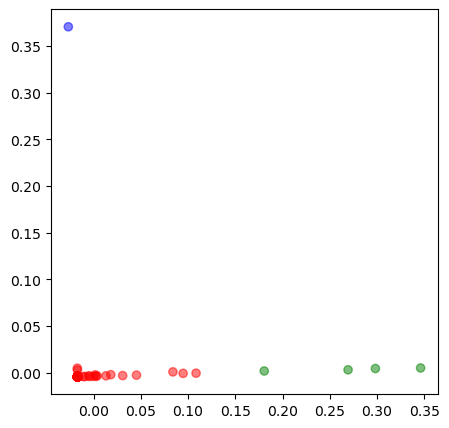

In [20]:
%env OMP_NUM_THREADS=1
kmeans = KMeans(n_clusters=3, max_iter =300)
kmeans.fit(df)

labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

fig = plt.figure(figsize=(5, 5))
colmap = {1: 'r', 2: 'g', 3: 'b'}
colors = list(map(lambda x: colmap[x+1], labels))
plt.scatter(df['x1'], df['x2'], color=colors, alpha=0.5, edgecolor=colors)

env: OMP_NUM_THREADS=1


C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


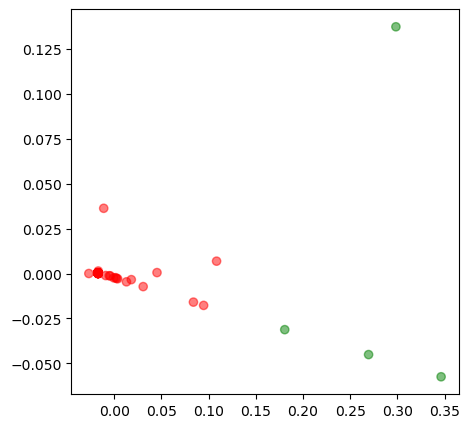

In [21]:
%env OMP_NUM_THREADS=1
kmeans = KMeans(n_clusters=2, max_iter =300)
kmeans.fit(df)

labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

fig = plt.figure(figsize=(5, 5))
colmap = {1: 'r', 2: 'g', 3: 'b'}
colors = list(map(lambda x: colmap[x+1], labels))
plt.scatter(df['x1'], df['x3'], color=colors, alpha=0.5, edgecolor=colors)


env: OMP_NUM_THREADS=1


C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


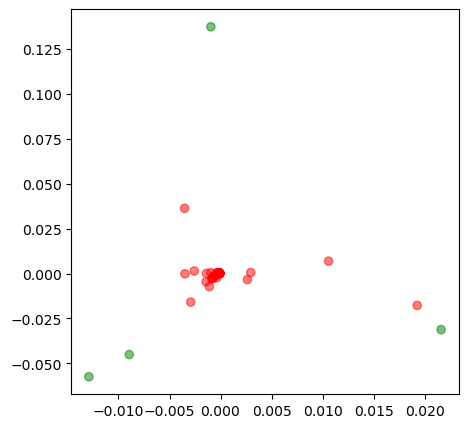

In [22]:
%env OMP_NUM_THREADS=1
kmeans = KMeans(n_clusters=2, max_iter =300)
kmeans.fit(df)

labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

fig = plt.figure(figsize=(5, 5))
colmap = {1: 'r', 2: 'g', 3: 'b'}
colors = list(map(lambda x: colmap[x+1], labels))
plt.scatter(df['x5'], df['x3'], color=colors, alpha=0.5, edgecolor=colors)

env: OMP_NUM_THREADS=1


C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Adhip Maitra\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


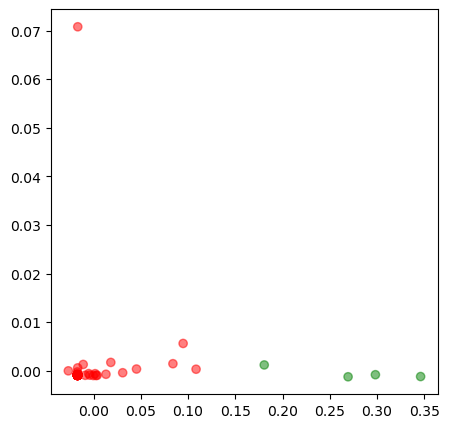

In [23]:
%env OMP_NUM_THREADS=1
kmeans = KMeans(n_clusters=2, max_iter =300)
kmeans.fit(df)

labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

fig = plt.figure(figsize=(5, 5))
colmap = {1: 'r', 2: 'g', 3: 'b'}
colors = list(map(lambda x: colmap[x+1], labels))
plt.scatter(df['x1'], df['x4'], color=colors, alpha=0.5, edgecolor=colors)

In [24]:
kfold = 10
X = X_embedding
y = y

random_state = 1

test_F1 = np.zeros(kfold)
skf = KFold(n_splits = kfold, shuffle = True, random_state = random_state)
k = 0
epochs = 500
batch_size = 10

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    model = Sequential()
    model.add(Dense(64, input_shape = (X_train.shape[1],))) 
    model.add(Activation('relu'))
    model.add(Dropout(0.5))
    model.add(Dense(32))
    model.add(Activation('relu'))
    model.add(Dropout(0.5))
    model.add(Dense(1))
    model.add(Activation('sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    
    history = model.fit(X_train, y_train, validation_split=0.2, batch_size=batch_size, epochs=epochs, verbose=1)
    
    y_pred = model.predict(X_test).round().astype(int)
    y_train_pred = model.predict(X_train).round().astype(int)

    test_F1[k] = sklearn.metrics.f1_score(y_test, y_pred)
    k+=1
    
print ('Average f1 score', np.mean(test_F1))

3/3 [==============================] - 0s 1ms/step
Average f1 score 0.934660633484163


In [25]:
from keras.models import load_model

model.save('my_model.h5')  # creates a HDF5 file 'my_model.h5'

print("model saved!!!")

model saved!!!


In [26]:
model2 = load_model('my_model.h5')
model.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_27 (Dense)            (None, 64)                28288     
                                                                 
 activation_27 (Activation)  (None, 64)                0         
                                                                 
 dropout_18 (Dropout)        (None, 64)                0         
                                                                 
 dense_28 (Dense)            (None, 32)                2080      
                                                                 
 activation_28 (Activation)  (None, 32)                0         
                                                                 
 dropout_19 (Dropout)        (None, 32)                0         
                                                                 
 dense_29 (Dense)            (None, 1)                

In [27]:
#Check with Test Data
df_test = pd.read_csv('TestDataSet.csv',low_memory=False)
df_test = df_test.drop(columns=['Unnamed: 3'])
df_test = df_test.replace('\n','', regex=True)
df_test['S-Protein'] = df_test['S-Protein'].str.strip(r'\\r')
Xnew = df_test['S-Protein'].apply(str)
test_sequences = [split(x) for x in Xnew]
identifier=df_test['Identifier'].apply(str).tolist()
corpus_new = pd.DataFrame(
    {'id': identifier,
     'sequence': test_sequences,
    })
corpus_new = corpus_new.dropna(axis=1)
corpus_new = corpus_new.reset_index(drop=True) 
embedding_new = sgt.fit_transform(corpus_new)
X_new = embedding_new.set_index('id')
#X_new = embedding_new.drop(columns=['id'])
# make a prediction
#ynew = model.predict(X_new)
# show the inputs and predicted outputs
#for i in range(len(ynew)):
 #print("identifier=%s, Predicted=%s" % (identifier[i], ynew[i]))

In [28]:
X_new

,"(A, A)","(A, C)","(A, D)","(A, E)","(A, F)","(A, G)","(A, H)","(A, I)","(A, K)","(A, L)",...,"(Y, N)","(Y, P)","(Y, Q)","(Y, R)","(Y, S)","(Y, T)","(Y, V)","(Y, W)","(Y, X)","(Y, Y)"
id,,,,,,,,,,,,,,,,,,,,,
OR575624.1,0.001247,0.000339,0.001197,0.001076,0.000555,0.001309,0.001230,0.001065,0.000467,0.001039,...,0.001042,0.000856,0.001022,0.001110,0.000961,0.000862,0.000927,0.000942,0.000000,0.001103
UJK14488.1,0.001273,0.000316,0.001209,0.001090,0.000395,0.001353,0.001074,0.001008,0.000416,0.001072,...,0.001102,0.000907,0.001080,0.001167,0.001141,0.000914,0.000980,0.000995,0.000000,0.000930
QTZ19244.1,0.001305,0.000227,0.001238,0.001103,0.000325,0.001090,0.001944,0.001088,0.000427,0.001053,...,0.000943,0.000958,0.001213,0.001428,0.001008,0.000871,0.000729,0.000961,0.000000,0.001261
WBQ65914.2,0.001279,0.000345,0.001058,0.001094,0.000510,0.001357,0.001077,0.001091,0.000473,0.001069,...,0.000788,0.000899,0.001070,0.001539,0.001012,0.000916,0.000968,0.000989,0.000748,0.000836
QZQ30931.1,0.001273,0.000303,0.001212,0.001075,0.000321,0.001197,0.001588,0.001077,0.000439,0.001055,...,0.000926,0.000960,0.001212,0.001437,0.001024,0.000878,0.000774,0.000970,0.000000,0.001214
QZQ31266.1,0.001306,0.000310,0.001238,0.001027,0.000329,0.001226,0.001616,0.001217,0.000449,0.000978,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000878,0.000775,0.000970,0.000000,0.001214
QZQ31201.1,0.001273,0.000303,0.001212,0.001075,0.000321,0.001197,0.001588,0.001119,0.000439,0.001055,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000873,0.000774,0.000970,0.000000,0.001214
QZQ31904.1,0.001273,0.000303,0.001212,0.001075,0.000321,0.001197,0.001588,0.001077,0.000439,0.001055,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000878,0.000774,0.000970,0.000000,0.001214
QZQ31816.1,0.001273,0.000303,0.001212,0.001075,0.000321,0.001197,0.001588,0.001077,0.000439,0.001055,...,0.000926,0.000960,0.001212,0.001437,0.001023,0.000878,0.000774,0.000970,0.000000,0.001214


In [29]:
pca.fit(X_new)
X_new_pca = pca.transform(X_new)

In [30]:
X_new_pca

array([[-0.00958746,  0.00227668, -0.00003344,  0.00101861, -0.00001711],
       [-0.00958349,  0.00289494,  0.00002118, -0.00084056,  0.00001439],
       [-0.00966708, -0.00063543,  0.0018934 ,  0.00000239,  0.00000425],
       [ 0.09650249, -0.00000396,  0.00000002, -0.0000001 , -0.        ],
       [-0.00966642, -0.00064951, -0.00026023, -0.00003365, -0.00008331],
       [-0.0096658 , -0.00064939, -0.00028807,  0.00003511,  0.00041114],
       [-0.00966643, -0.00063164, -0.00027101, -0.00007907, -0.00007166],
       [-0.00966645, -0.00065043, -0.00026546, -0.00002568, -0.00006442],
       [-0.00966645, -0.00065043, -0.00026546, -0.00002568, -0.00006442],
       [-0.00966645, -0.00065043, -0.00026546, -0.00002568, -0.00006442],
       [-0.00966645, -0.00065043, -0.00026546, -0.00002568, -0.00006442]])

In [31]:
#make a prediction
ynew = model.predict(X_new)
# show the inputs and predicted outputs
for i in range(len(ynew)):
 print("identifier=%s, Predicted=%s" % (identifier[i], ynew[i]))

1/1 [==============================] - 0s 10ms/step
identifier=OR575624.1, Predicted=[0.02667185]
identifier=UJK14488.1, Predicted=[0.01193085]
identifier=QTZ19244.1, Predicted=[0.6688085]
identifier=WBQ65914.2, Predicted=[0.24388249]
identifier=QZQ30931.1, Predicted=[0.93952286]
identifier=QZQ31266.1, Predicted=[0.9400195]
identifier=QZQ31201.1, Predicted=[0.93887836]
identifier=QZQ31904.1, Predicted=[0.9397233]
identifier=QZQ31816.1, Predicted=[0.9397234]
identifier=QZQ31673.1, Predicted=[0.9397234]
identifier=QZQ31585.1, Predicted=[0.9397234]


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


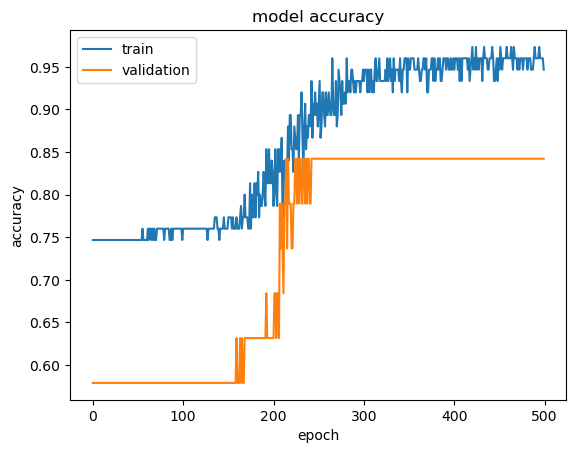

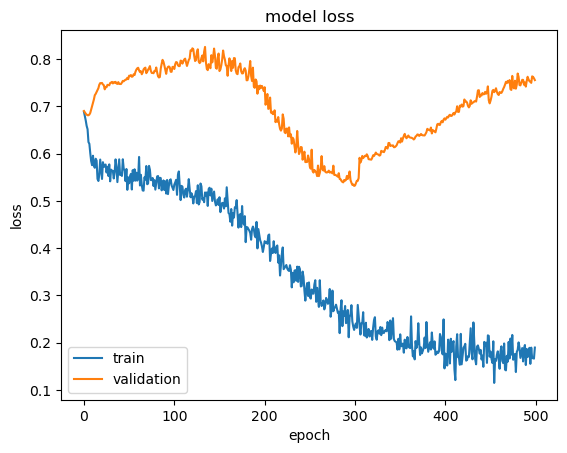

In [32]:
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()

In [33]:
#!pip install keras_tuner --upgrade

In [34]:
(X_train.shape, y_train.shape), (X_test.shape, y_test.shape)

(((94, 441), (94,)), ((10, 441), (10,)))

In [35]:
import keras_tuner as kt
def model_builder(hp):
    model = tf.keras.Sequential()
    #model.add(tf.keras.layers.Flatten(input_shape = (X_train.shape[1],)))
    #model.add(Dense(64, input_shape = (X_train.shape[1],)))

    hp_activation = hp.Choice('activation', values=['relu', 'tanh'])
    hp_layer_1 = hp.Int('layer_1', min_value=16, max_value=128, step=16)   
    hp_layer_2 = hp.Int('layer_1', min_value=16, max_value=128, step=16)
    hp_learning_rate = hp.Choice('learning_rate', values = [1e-2, 1e-3, 1e-4])

    model.add(tf.keras.layers.Dense(units=hp_layer_1, activation = hp_activation))           
    #model.add(Dropout(0.5))
    model.add(tf.keras.layers.Dense(units=hp_layer_2, activation = hp_activation))
    #model.add(Dropout(0.5))
    model.add(tf.keras.layers.Dense(1, activation ='sigmoid'))
   
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate) , loss=tf.keras.losses.BinaryCrossentropy(), metrics=['accuracy'])

    return model

In [36]:
tuner = kt.Hyperband(model_builder,
                     objective = 'val_accuracy',
                     max_epochs = 1000,
                     factor = 3, 
                     directory = 'covid_model',
                     project_name = 'covid_genomics')

In [37]:
stop_early = tf.keras.callbacks.EarlyStopping(monitor ='val_loss', patience = 5)

In [38]:
tuner.search(X_train, y_train, epochs=1000, validation_split=0.2, callbacks=[stop_early])

Trial 45 Complete [00h 00m 01s]
val_accuracy: 0.5789473652839661

Best val_accuracy So Far: 0.6315789222717285
Total elapsed time: 00h 00m 22s


In [39]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

In [40]:
model = tuner.hypermodel.build(best_hps)
history = model.fit(X_train, y_train, epochs=500, validation_split=0.2, callbacks=[stop_early])

Epoch 1/500
3/3 [==============================] - 0s 43ms/step - loss: 0.6929 - accuracy: 0.6400 - val_loss: 0.6930 - val_accuracy: 0.5789
Epoch 2/500
3/3 [==============================] - 0s 9ms/step - loss: 0.6922 - accuracy: 0.7467 - val_loss: 0.6927 - val_accuracy: 0.5789
Epoch 3/500
3/3 [==============================] - 0s 8ms/step - loss: 0.6914 - accuracy: 0.7600 - val_loss: 0.6925 - val_accuracy: 0.5789
Epoch 4/500
3/3 [==============================] - 0s 8ms/step - loss: 0.6907 - accuracy: 0.7600 - val_loss: 0.6924 - val_accuracy: 0.5789
Epoch 5/500
3/3 [==============================] - 0s 7ms/step - loss: 0.6900 - accuracy: 0.7600 - val_loss: 0.6921 - val_accuracy: 0.5789
Epoch 6/500
3/3 [==============================] - 0s 8ms/step - loss: 0.6892 - accuracy: 0.7600 - val_loss: 0.6919 - val_accuracy: 0.5789
Epoch 7/500
3/3 [==============================] - 0s 8ms/step - loss: 0.6883 - accuracy: 0.7600 - val_loss: 0.6916 - val_accuracy: 0.5789
Epoch 8/500
3/3 [=========

In [41]:
pd.DataFrame(history.history)

,loss,accuracy,val_loss,val_accuracy
0,0.692938,0.640000,0.692996,0.578947
1,0.692193,0.746667,0.692745,0.578947
2,0.691432,0.760000,0.692546,0.578947
3,0.690694,0.760000,0.692357,0.578947
4,0.689996,0.760000,0.692126,0.578947
5,0.689169,0.760000,0.691876,0.578947
6,0.688337,0.760000,0.691624,0.578947
7,0.687461,0.760000,0.691391,0.578947
8,0.686565,0.760000,0.691151,0.578947
9,0.685669,0.746667,0.690913,0.578947


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


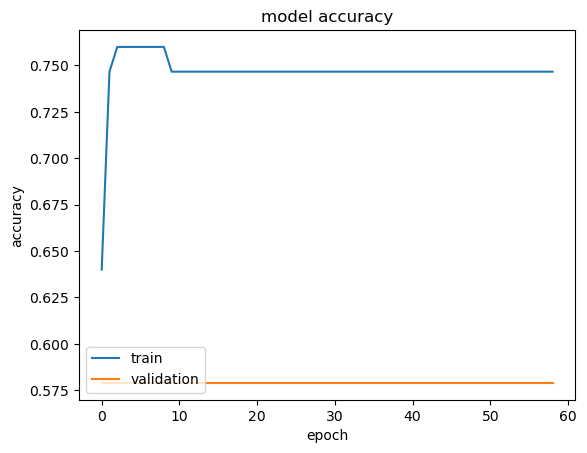

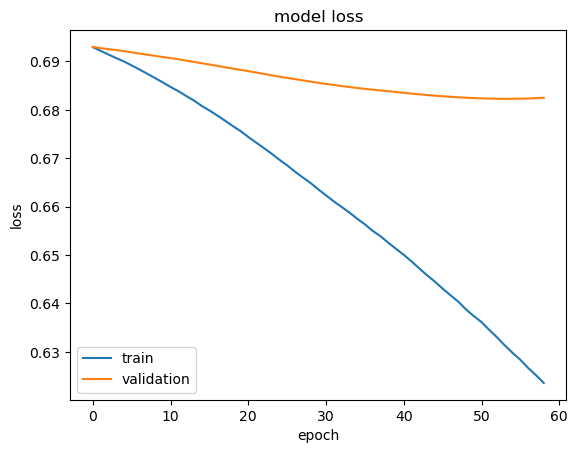

In [42]:
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()